# Part 2 – Washing-machine use in 6 homes

Data: the **official cleaned** REFIT files, at 1-minute resolution.
Homes: **1, 2, 5, 7, 8, 9** (the readme lists a washing machine on a plug in these homes).
Period: the full recording period of each home (see the table below).
The washing-machine column is different in each home (from the readme):

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CLEAN = "../CLEAN_REFIT_081116/"
plt.rcParams["figure.figsize"] = (12, 4)

WM_COLUMN = {1: "Appliance5", 2: "Appliance2", 5: "Appliance3", 7: "Appliance5", 8: "Appliance4", 9: "Appliance3"}
HOUSES = list(WM_COLUMN)

## 1. Load each home

Same cleaning rules as in Part 1: sort, remove duplicate timestamps, 1-minute mean, remove frozen sensors
(the official data is forward-filled, so dead sensors show up as flat lines), fill gaps ≤ 5 min.

In [2]:
def run_length(mask):
    """For every row: how long is the run of equal True/False values it belongs to."""
    run_id = (mask != mask.shift()).cumsum()
    return mask.groupby(run_id).transform("size")


def frozen(s, minutes=30):
    """True where a sensor repeats exactly the same non-zero value for 30+ minutes.
    Small gaps (<= 5 min) inside the flat line are bridged with the last known value."""
    last = s.ffill(limit=5)
    same = (last.diff() == 0) & (last > 30)
    return same & (run_length(same) >= minutes) & s.notna()


def fill_short_gaps(s, max_gap=5):
    """Interpolate gaps of up to 5 minutes; longer gaps stay empty."""
    missing = s.isna()
    short = missing & (run_length(missing) <= max_gap)
    return s.where(~short, s.interpolate(limit_area="inside"))

In [3]:
def load_house(house):
    df = pd.read_csv(f"{CLEAN}CLEAN_House{house}.csv", usecols=["Unix", "Aggregate", WM_COLUMN[house]])
    df = df.rename(columns={"Aggregate": "aggregate", WM_COLUMN[house]: "wm"})
    df.index = pd.to_datetime(df.pop("Unix"), unit="s", utc=True).rename("time")
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="first")]

    m = df.resample("1min").mean()
    m["frozen"] = frozen(m["aggregate"]) | frozen(m["wm"])
    m.loc[m["frozen"], ["aggregate", "wm"]] = np.nan
    m["missing"] = m["aggregate"].isna()
    m["aggregate"] = fill_short_gaps(m["aggregate"])
    m["wm"] = fill_short_gaps(m["wm"])
    return m


houses = {}
for h in HOUSES:
    houses[h] = load_house(h)
    print("House", h, "loaded:", len(houses[h]), "minutes")

House 1 loaded: 920091 minutes


House 2 loaded: 889078 minutes


House 5 loaded: 933593 minutes


House 7 loaded: 882970 minutes


House 8 loaded: 799284 minutes


House 9 loaded: 818007 minutes


In [4]:
houses[2].head()

,aggregate,wm,frozen,missing
time,,,,
2013-09-17 22:08:00+00:00,697.571429,0.0,False,False
2013-09-17 22:09:00+00:00,650.800000,0.0,False,False
2013-09-17 22:10:00+00:00,813.900000,0.0,False,False
2013-09-17 22:11:00+00:00,743.000000,0.0,False,False
2013-09-17 22:12:00+00:00,688.625000,0.0,False,False


In [5]:
houses[2][["aggregate", "wm"]].describe().round(1)

,aggregate,wm
count,663807.0,663807.0
mean,460.9,18.3
std,1031.6,171.8
min,47.5,0.0
25%,107.8,0.0
50%,168.7,0.0
75%,334.9,0.0
max,15341.8,2250.6


## 2. When is a wash happening? (the cycle rule)

1. The machine is **on** in a minute when it uses **more than 20 W** (standby is 0–5 W, any real
   washing step uses 100 W or more).
2. Washes have **pauses** (soaking, filling with water). On-minutes with gaps of **≤ 10 minutes**
   between them belong to the **same wash**.
3. A wash must last **at least 10 minutes** and use **at least 0.05 kWh** (this removes tiny blips).

In [6]:
def detect_cycles(wm):
    on_positions = np.flatnonzero((wm > 20).to_numpy())          # minutes where the machine is on
    new_cycle = np.diff(on_positions, prepend=-100) > 11          # more than 10 off-minutes since last on-minute
    cycle_id = np.cumsum(new_cycle)
    values = wm.fillna(0).to_numpy()

    rows = []
    for k in np.unique(cycle_id):
        first, last = on_positions[cycle_id == k][[0, -1]]
        power = values[first:last + 1]
        rows.append({"start": wm.index[first],
                     "duration_min": last - first + 1,
                     "peak_w": power.max(),
                     "energy_kwh": power.sum() / 60 / 1000})    # W per minute -> kWh
    cycles = pd.DataFrame(rows)
    return cycles[(cycles["duration_min"] >= 10) & (cycles["energy_kwh"] >= 0.05)].reset_index(drop=True)


cycles = {h: detect_cycles(houses[h]["wm"]) for h in HOUSES}
cycles[2].head()

,start,duration_min,peak_w,energy_kwh
0,2013-09-20 07:50:00+00:00,95,2095.600000,1.204571
1,2013-09-22 09:08:00+00:00,158,2118.800000,0.768510
2,2013-09-23 19:13:00+00:00,134,2118.500000,1.282812
3,2013-09-25 13:21:00+00:00,172,2109.900000,0.832900
4,2013-09-26 09:22:00+00:00,100,2079.545455,1.029941


## 3. Data availability, quality and number of cycles

In [7]:
rows = []
for h in HOUSES:
    df, c = houses[h], cycles[h]
    days = (df.index[-1] - df.index[0]).days
    wm = df["wm"].dropna()
    rows.append({"house": h,
                 "start": df.index[0].date(), "end": df.index[-1].date(), "days": days,
                 "% minutes missing": round(100 * df["missing"].mean(), 1),
                 "% frozen (removed)": round(100 * df["frozen"].mean(), 2),
                 "% time WM off": round(100 * (wm <= 20).mean(), 1),
                 "cycles": len(c),
                 "cycles per week": round(len(c) / days * 7, 1),
                 "median duration (min)": c["duration_min"].median(),
                 "median peak (W)": round(c["peak_w"].median()),
                 "median kWh per cycle": round(c["energy_kwh"].median(), 2)})
summary = pd.DataFrame(rows)
summary

,house,start,end,days,% minutes missing,% frozen (removed),% time WM off,cycles,cycles per week,median duration (min),median peak (W),median kWh per cycle
0,1,2013-10-09,2015-07-10,638,13.0,0.33,98.2,393,4.3,33.0,2326,0.32
1,2,2013-09-17,2015-05-28,617,25.4,0.77,95.3,334,3.8,97.0,2090,0.61
2,5,2013-09-26,2015-07-06,648,11.7,2.36,94.6,701,7.6,42.0,2074,0.29
3,7,2013-11-01,2015-07-08,613,13.2,0.62,91.6,855,9.8,60.0,2083,0.54
4,8,2013-11-01,2015-05-10,555,11.4,1.13,96.7,363,4.6,61.0,2338,0.81
5,9,2013-12-17,2015-07-08,568,20.1,4.72,97.2,247,3.0,73.0,2210,0.65


**What the table shows**
- Each home has about **1.5–1.8 years** of data. 11–25 % of minutes are missing (House 2 the most), and 0.3–4.7 % were
  frozen sensors.
- The washing machine is **off 92–98 % of the time**. This is important for Part 3: a model that always says "off" is
  right most of the time but useless.
- **3–10 washes per week**. The two 4-person homes (5 and 7) wash the most.
- Every machine peaks at about **2.1–2.3 kW**: the water heater. This is what we hope to find in the whole-house signal.
  It also confirms we picked the right column for each home.

## 4. When do people wash?

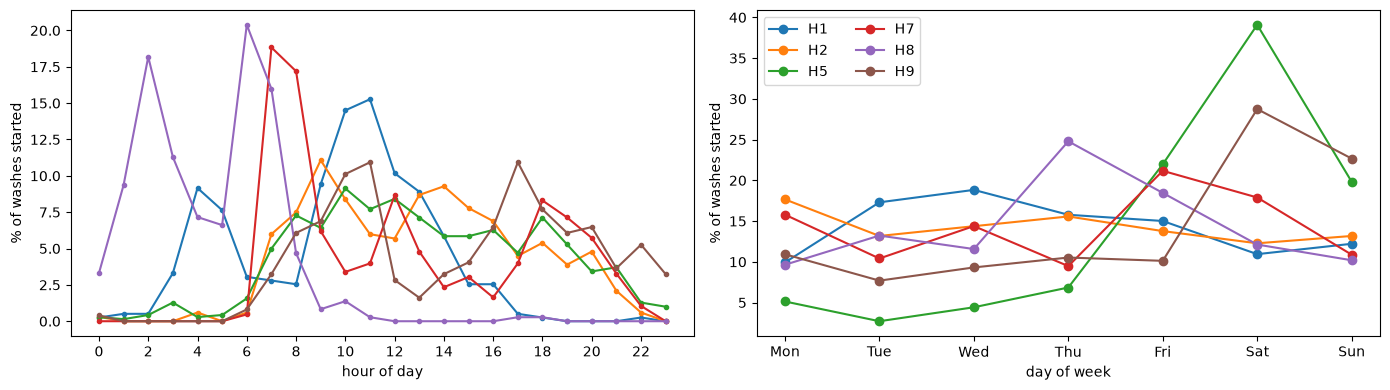

In [8]:
all_cycles = pd.concat([c.assign(house=h) for h, c in cycles.items()], ignore_index=True)
local_start = all_cycles["start"].dt.tz_convert("Europe/London")   # UK clock time
all_cycles["hour"] = local_start.dt.hour
all_cycles["weekday"] = local_start.dt.day_of_week                 # 0 = Monday

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for h in HOUSES:
    c = all_cycles[all_cycles["house"] == h]
    (c["hour"].value_counts(normalize=True).sort_index() * 100).reindex(range(24), fill_value=0).plot(ax=axes[0], marker=".", label=f"H{h}")
    (c["weekday"].value_counts(normalize=True).sort_index() * 100).reindex(range(7), fill_value=0).plot(ax=axes[1], marker="o", label=f"H{h}")
axes[0].set(xlabel="hour of day", ylabel="% of washes started", xticks=range(0, 24, 2))
axes[1].set(xlabel="day of week", ylabel="% of washes started", xticks=range(7), xticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].legend(ncol=2)
plt.tight_layout(); plt.savefig("../figures/part2_usage_patterns.png", dpi=110); plt.show()

In [9]:
period = pd.cut(all_cycles["hour"], [0, 6, 12, 17, 24], right=False, labels=["night 0-6", "morning 6-12", "afternoon 12-17", "evening 17-24"])
table = (pd.crosstab(all_cycles["house"], period, normalize="index") * 100).round(1)
table["% at weekend"] = (all_cycles.groupby("house")["weekday"].apply(lambda d: (d >= 5).mean()) * 100).round(1)
table

hour,night 0-6,morning 6-12,afternoon 12-17,evening 17-24,% at weekend
house,,,,,
1,21.4,47.6,30.0,1.0,23.2
2,0.9,39.5,38.3,21.3,25.4
5,2.9,37.1,33.5,26.5,58.9
7,0.0,50.1,20.5,29.5,28.8
8,55.9,43.5,0.0,0.6,22.3
9,0.4,38.1,18.2,43.3,51.4


In [10]:
peak = all_cycles["hour"].between(16, 19)    # 16:00-20:00, the evening peak on the grid
print("washes starting in the 16-20h peak: %.1f%% of all %d washes" % (100 * peak.mean(), len(all_cycles)))
print((all_cycles[peak].groupby("house").size() / all_cycles.groupby("house").size() * 100).round(1))

washes starting in the 16-20h peak: 17.5% of all 2893 washes
house
1     3.3
2    20.7
5    23.4
7    21.1
8     0.6
9    31.2
dtype: float64


**When people wash**
- Most washes start in the **morning**.
- **House 8 washes at night** (56 %, peak around 2 am), House 1 partly (21 %). That suggests a cheap night tariff and a
  delay timer.
- **House 9 does 43 % of its washes in the evening**, and Houses 5 and 9 wash mostly at **weekends** (59 % and 51 %;
  28.6 % would mean no preference).
- Overall **17.5 % of washes start between 16:00 and 20:00**, when the grid is busiest (31 % in House 9).

## 5. Plots

### (i) A representative day (House 2)

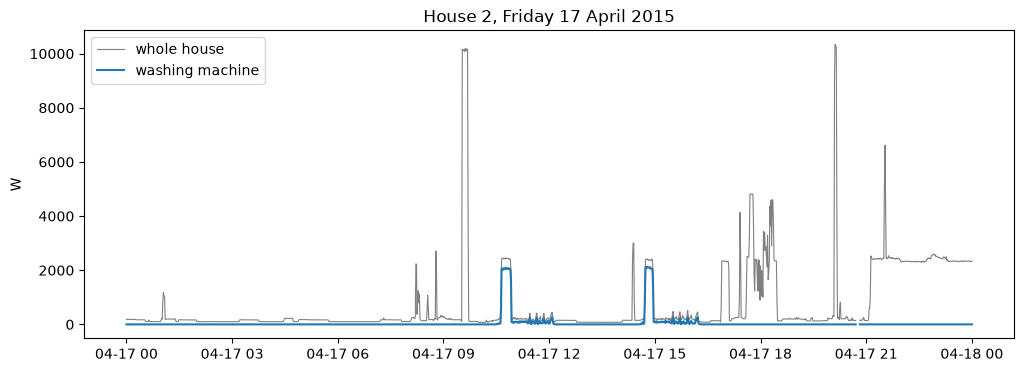

In [11]:
c = cycles[2]
typical = c.iloc[(c["energy_kwh"] - c["energy_kwh"].median()).abs().argmin()]   # most typical wash
day = typical["start"].tz_convert("Europe/London").normalize()
d = houses[2].tz_convert("Europe/London").loc[day:day + pd.Timedelta("1D")]

plt.plot(d["aggregate"], color="grey", lw=0.8, label="whole house")
plt.plot(d["wm"], color="tab:blue", label="washing machine")
plt.title(f"House 2, {day:%A %d %B %Y}"); plt.ylabel("W"); plt.legend()
plt.savefig("../figures/part2_representative_day.png", dpi=110); plt.show()

House 2 did two washes that day. Each shows up in the whole-house signal as a **~2 kW block for about 15–20 minutes**
(heating the water), then a long low tail (drum turning and spinning, 100–500 W).

There are also **look-alikes**: around 17:00 another ~2.3 kW block appears that is *not* the washing machine (probably
the dishwasher), and the 10 kW spikes are an electric shower. Telling these apart is the hard part of Part 3.

### (ii) Detected cycles – the most typical wash of each home

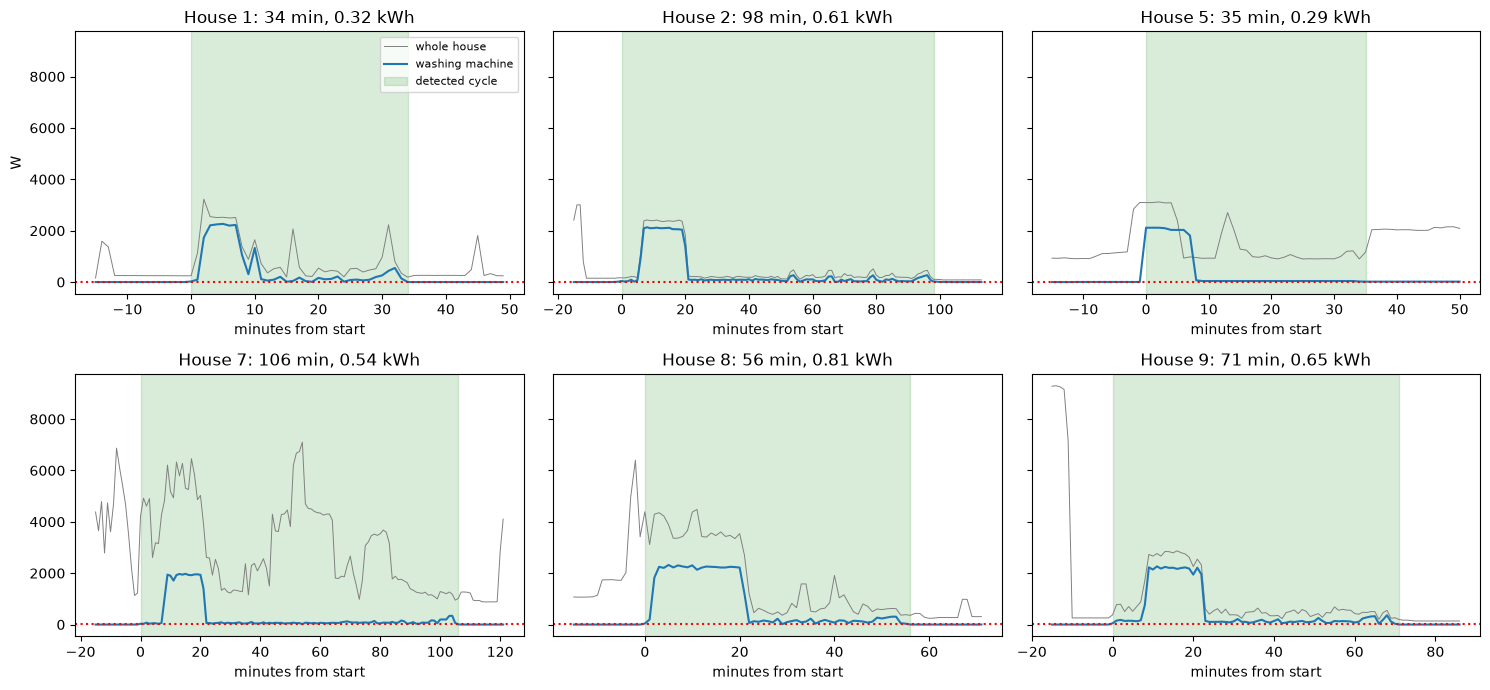

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, h in zip(axes.flat, HOUSES):
    c = cycles[h]
    t = c.iloc[(c["energy_kwh"] - c["energy_kwh"].median()).abs().argmin()]
    end = t["start"] + pd.Timedelta(minutes=int(t["duration_min"]))
    seg = houses[h].loc[t["start"] - pd.Timedelta("15min"):end + pd.Timedelta("15min")]
    minutes = (seg.index - t["start"]).total_seconds() / 60
    ax.plot(minutes, seg["aggregate"], color="grey", lw=0.7, label="whole house")
    ax.plot(minutes, seg["wm"], color="tab:blue", label="washing machine")
    ax.axvspan(0, t["duration_min"], color="green", alpha=0.15, label="detected cycle")
    ax.axhline(20, color="red", ls=":")
    ax.set_title(f"House {h}: {t['duration_min']} min, {t['energy_kwh']:.2f} kWh")
    ax.set_xlabel("minutes from start")
axes[0, 0].set_ylabel("W"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("../figures/part2_example_cycles.png", dpi=110); plt.show()

Green is the detected cycle, the red dotted line is the 20 W threshold. The rule catches each wash as one piece,
including the pauses. Programmes differ a lot: about 30 minutes in House 1, about 100 minutes in Houses 2 and 7.

### (iii) Comparing homes

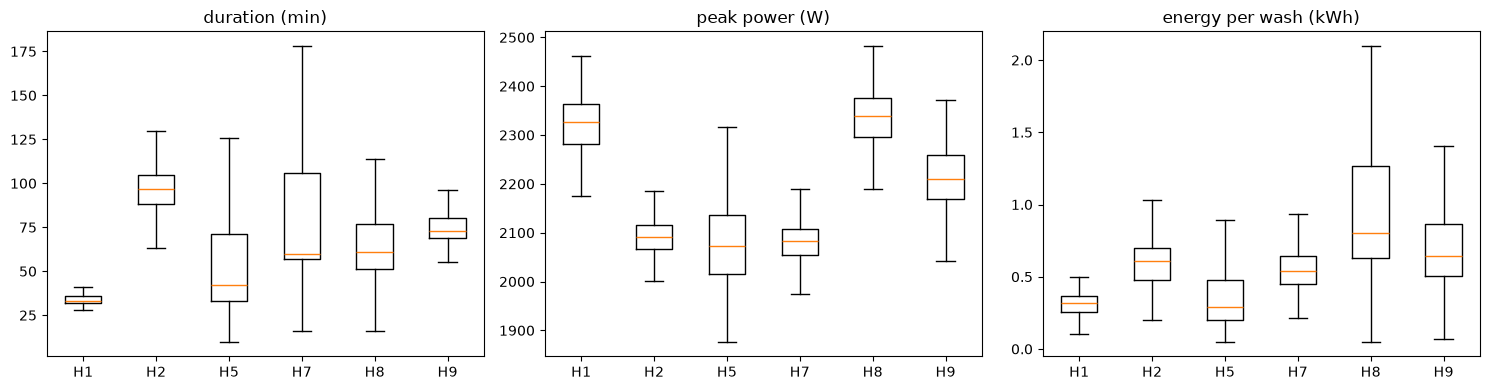

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["duration_min", "peak_w", "energy_kwh"], ["duration (min)", "peak power (W)", "energy per wash (kWh)"]):
    ax.boxplot([cycles[h][col] for h in HOUSES], tick_labels=[f"H{h}" for h in HOUSES], showfliers=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig("../figures/part2_cross_house.png", dpi=110); plt.show()

- **Duration** differs most between homes (median 33 min in House 1 vs 97 min in House 2).
- **Peak power** is similar everywhere (2.1–2.3 kW): all machines have a similar heater.
- **Energy per wash** differs almost 3x (0.29 kWh in House 5 vs 0.81 kWh in House 8), mainly from the programme and
  temperature chosen.

Homes are quite different from each other, so a model trained on some homes will find a new home hard.

In [14]:
# save the 1-minute data for Part 3, so we don't have to read the big CSV files again
pd.to_pickle(houses, "../data/houses_1min.pkl")